# UAS PPD: Prediksi Keberhasilan Telemarketing Bank (versi perbaikan)

Lanjutan notebook UTS (`01_uts_baseline.ipynb`). Hasil evaluasi UTS menunjukkan beberapa kelemahan yang diperbaiki di sini:

1. **Tuning hampir acak**: CV AUC GridSearch UTS hanya 0,51-0,54, sehingga hyperparameter terpilih tidak bisa dipercaya.
2. **Skema validasi tidak konsisten**: tuning memakai `TimeSeriesSplit`, fase modeling memakai split acak, dan data uji memakai split waktu 80/20.
3. **Threshold 0,5 tidak cocok**: SVM menebak semua nasabah `yes`, LR recall 0,93 dengan precision 0,35.
4. **Decision Tree jatuh** dari AUC 0,655 (validasi) ke 0,547 (uji).
5. **Model terbatas**: belum ada Random Forest dan gradient boosting.
6. Belum ada **interpretasi fitur**, **kalibrasi probabilitas**, dan **model yang siap di-deploy**.

Perbaikan: validasi *rolling window* kronologis, model tambahan (Random Forest, HistGradientBoosting, LightGBM, soft voting), evaluasi berbasis kapasitas telepon (top-k%) menggantikan threshold 0,5, permutation importance, kalibrasi Platt, dan ekspor artefak untuk API dan dashboard.

In [1]:
import sys, json, time, warnings
from datetime import date
from pathlib import Path
sys.path.insert(0, '../src')

import joblib, sklearn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

from bank_marketing.features import SEED, RAW_FEATURES, load_data, build_models
from bank_marketing.evaluation import (chronological_split, rolling_window_splits, get_scores, rank_metrics,
                                       threshold_metrics, capture_at)
from bank_marketing.tuning import tune_models, apply_params, build_voting, VOTING_NAME
from bank_marketing.model import PlattCalibrated, oof_scores
from bank_marketing import export

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.0)
PALETTE = ['#4F86C6', '#2A9D8F', '#8E7DBE', '#F28482', '#E9C46A', '#F4A261', '#7FB069']
ARTIFACTS = Path('../artifacts'); ARTIFACTS.mkdir(exist_ok=True)

# 1. Data dan pergeseran waktu

Dataset berurutan secara kronologis (Mei 2008 sampai November 2010). Data dimuat tanpa `duration` (baru diketahui setelah telepon selesai, sehingga tidak boleh dipakai untuk prediksi sebelum menelepon) dan tanpa duplikat. Grafik di bawah menunjukkan alasan utama kesulitan data uji: rasio `yes` dan suku bunga `euribor3m` berubah drastis antar periode.

Rows: 41,176 | features: 19 | 'yes' rate: 11.27%
Train: 32,940 rows (6.38% yes) | Test (out-of-time): 8,236 rows (30.83% yes)


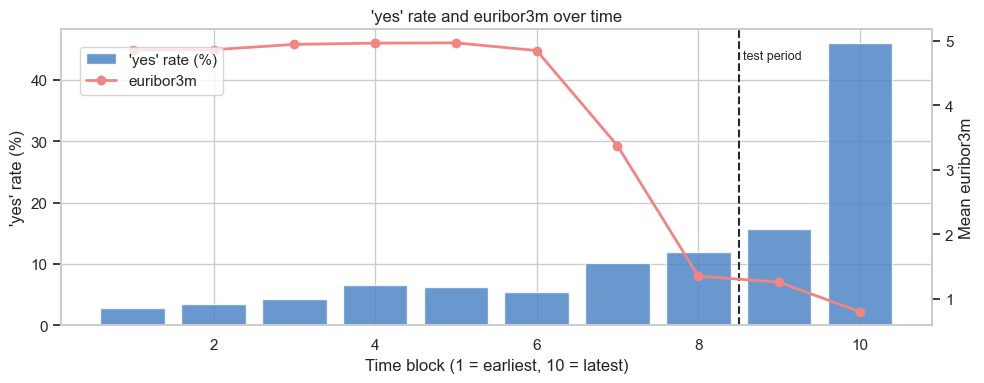

In [2]:
X, y = load_data()
tr, te = chronological_split(len(X), 0.2)
X_train, y_train, X_test, y_test = X.iloc[tr], y.iloc[tr], X.iloc[te], y.iloc[te]
print(f"Rows: {len(X):,} | features: {X.shape[1]} | 'yes' rate: {y.mean():.2%}")
print(f"Train: {len(X_train):,} rows ({y_train.mean():.2%} yes) | Test (out-of-time): {len(X_test):,} rows ({y_test.mean():.2%} yes)")

tl = pd.DataFrame(export.eda_summary(X, y, 10)['timeline'])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(tl['block'], tl['yes_rate'] * 100, color=PALETTE[0], alpha=.85, label="'yes' rate (%)")
ax.set_xlabel('Time block (1 = earliest, 10 = latest)'); ax.set_ylabel("'yes' rate (%)")
ax2 = ax.twinx(); ax2.plot(tl['block'], tl['euribor3m'], color=PALETTE[3], marker='o', lw=2, label='euribor3m')
ax2.set_ylabel('Mean euribor3m'); ax2.grid(False)
ax.axvline(8.5, color='#1F2937', ls='--'); ax.text(8.55, ax.get_ylim()[1] * .9, 'test period', fontsize=9)
ax.set_title("'yes' rate and euribor3m over time"); fig.legend(loc='upper left', bbox_to_anchor=(.08, .88)); plt.tight_layout(); plt.show()

# 2. Skema validasi

- **Out-of-time holdout**: 80% baris pertama untuk latih, 20% terakhir untuk uji (sama seperti UTS, sehingga hasil bisa dibandingkan).
- **Rolling window untuk tuning**: di dalam data latih, jendela latih berukuran tetap (5 blok) digeser maju dan diuji pada blok sesudahnya, sehingga validasi selalu mengevaluasi masa depan relatif terhadap data latih.
- **Rolling window seluruh timeline**: dipakai sebagai uji ketahanan (6 lipatan) di bagian 5.

In [3]:
tune_splits = rolling_window_splits(len(X_train), n_folds=3, train_blocks=5)
roll_splits = rolling_window_splits(len(X), n_folds=6, train_blocks=6)
fold_tbl = pd.DataFrame([{'Scheme': s, 'Fold': i + 1, 'Train rows': len(a), 'Test rows': len(b),
                          "Test 'yes' rate": yy.iloc[b].mean(), 'Test mean euribor3m': XX.iloc[b]['euribor3m'].mean()}
                         for s, sp, XX, yy in [('Tuning (train period)', tune_splits, X_train, y_train), ('Robustness (full timeline)', roll_splits, X, y)]
                         for i, (a, b) in enumerate(sp)])
display(fold_tbl.style.format({"Test 'yes' rate": '{:.1%}', 'Test mean euribor3m': '{:.2f}'}).hide(axis='index'))

Scheme,Fold,Train rows,Test rows,Test 'yes' rate,Test mean euribor3m
Tuning (train period),1,20585,4117,5.5%,4.85
Tuning (train period),2,20585,4117,10.2%,3.37
Tuning (train period),3,20585,4117,12.0%,1.35
Robustness (full timeline),1,20586,3431,4.6%,4.96
Robustness (full timeline),2,20586,3431,6.1%,4.13
Robustness (full timeline),3,20586,3431,19.0%,1.60
Robustness (full timeline),4,20586,3431,6.5%,1.31
Robustness (full timeline),5,20586,3431,22.5%,1.17
Robustness (full timeline),6,20586,3431,48.4%,0.79


# 3. Hyperparameter tuning (rolling window)

`RandomizedSearchCV` dengan skor ROC-AUC pada lipatan rolling window. SVM dicari pada subsampel (setiap baris ke-6) karena kernel SVM lambat pada seluruh data. Catatan: AUC validasi yang mendekati 0,5 menunjukkan pola 2008 hanya sedikit membantu memprediksi periode berikutnya (lihat bagian 1), jadi hasil tuning tidak boleh dibaca terlalu tajam.

In [4]:
t0 = time.time()
best_params, tune_df, tune_cv = tune_models(X_train, y_train)
print(f"Total tuning time: {time.time() - t0:.0f}s")
display(tune_df.style.format({'Rolling CV AUC (mean)': '{:.3f}', 'Rolling CV AUC (std)': '{:.3f}'}).hide(axis='index'))

Logistic Regression    CV AUC 0.409 +/- 0.090  (4s)


Decision Tree          CV AUC 0.517 +/- 0.089  (6s)


SVM (RBF)              CV AUC 0.578 +/- 0.120  (9s)


Random Forest          CV AUC 0.516 +/- 0.112  (35s)


HistGradientBoosting   CV AUC 0.491 +/- 0.089  (44s)


LightGBM               CV AUC 0.521 +/- 0.109  (69s)
Total tuning time: 69s


Model,Rolling CV AUC (mean),Rolling CV AUC (std),Best params
Logistic Regression,0.409,0.090,{'C': 1.5702970884055387}
Decision Tree,0.517,0.089,"{'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 108}"
SVM (RBF),0.578,0.120,"{'C': 0.23102018878452935, 'gamma': 0.0003549878832196505}"
Random Forest,0.516,0.112,"{'max_depth': 11, 'max_features': 'sqrt', 'min_samples_leaf': 30}"
HistGradientBoosting,0.491,0.089,"{'l2_regularization': 0.29507066707905333, 'learning_rate': 0.06248547977119089, 'max_depth': 2, 'max_iter': 285, 'min_samples_leaf': 108}"
LightGBM,0.521,0.109,"{'colsample_bytree': 0.5290418060840998, 'learning_rate': 0.13394334706750485, 'min_child_samples': 119, 'n_estimators': 201, 'num_leaves': 6, 'reg_lambda': 0.0012087541473056963, 'subsample': 0.9879639408647978, 'subsample_freq': 1}"


# 4. Evaluasi out-of-time (data uji)

Semua model dilatih pada 80% data awal dan diuji pada 20% terakhir. Selain enam model tunggal, ditambahkan ensemble *soft voting* dari LR, Random Forest, dan LightGBM yang sudah di-tuning. Perbandingan utama memakai metrik yang tidak bergantung threshold: AUC, ALIFT, PR-AUC, dan proporsi nasabah `yes` yang terjangkau bila hanya menelepon 20% atau 50% nasabah dengan skor tertinggi.

In [5]:
def make_model(name):
    return build_voting(best_params) if name == VOTING_NAME else apply_params(build_models()[name], best_params[name])

MODEL_NAMES = list(best_params) + [VOTING_NAME]
MODEL_COLORS = dict(zip(MODEL_NAMES, PALETTE))
holdout_models, holdout_scores, rows = {}, {}, []
for name in MODEL_NAMES:
    t0 = time.time()
    m = make_model(name).fit(X_train, y_train)
    s = get_scores(m, X_test)
    holdout_models[name], holdout_scores[name] = m, s
    rows.append({'Model': name, **rank_metrics(y_test, s), 'Fit time (s)': time.time() - t0})
    print(f"{name:26s} AUC {rows[-1]['AUC']:.3f}  ({rows[-1]['Fit time (s)']:.0f}s)")
holdout_df = pd.DataFrame(rows).set_index('Model')

uts = pd.DataFrame({'AUC': [0.740, 0.547, 0.713], 'ALIFT': [0.666, 0.495, 0.647]},
                   index=['Logistic Regression (UTS)', 'Decision Tree (UTS)', 'SVM (RBF) (UTS)'])
display(holdout_df.style.format('{:.3f}').highlight_max(color='#359FA0', axis=0))
print('Referensi hasil UTS (data uji sama):'); display(uts)

Logistic Regression        AUC 0.681  (3s)


Decision Tree              AUC 0.490  (0s)


SVM (RBF)                  AUC 0.597  (40s)


Random Forest              AUC 0.728  (1s)


HistGradientBoosting       AUC 0.688  (1s)


LightGBM                   AUC 0.674  (0s)


Soft Voting (LR+RF+LGBM)   AUC 0.707  (4s)


,AUC,ALIFT,PR-AUC,Capture@20%,Capture@50%,Fit time (s)
Model,,,,,,
Logistic Regression,0.681,0.625,0.496,0.367,0.690,2.800
Decision Tree,0.490,0.447,0.317,0.184,0.375,0.223
SVM (RBF),0.597,0.567,0.438,0.323,0.592,40.370
Random Forest,0.728,0.658,0.534,0.382,0.729,1.412
HistGradientBoosting,0.688,0.630,0.514,0.387,0.685,0.589
LightGBM,0.674,0.621,0.491,0.364,0.666,0.256
Soft Voting (LR+RF+LGBM),0.707,0.644,0.524,0.387,0.698,3.833


Referensi hasil UTS (data uji sama):


,AUC,ALIFT
Logistic Regression (UTS),0.740,0.666
Decision Tree (UTS),0.547,0.495
SVM (RBF) (UTS),0.713,0.647


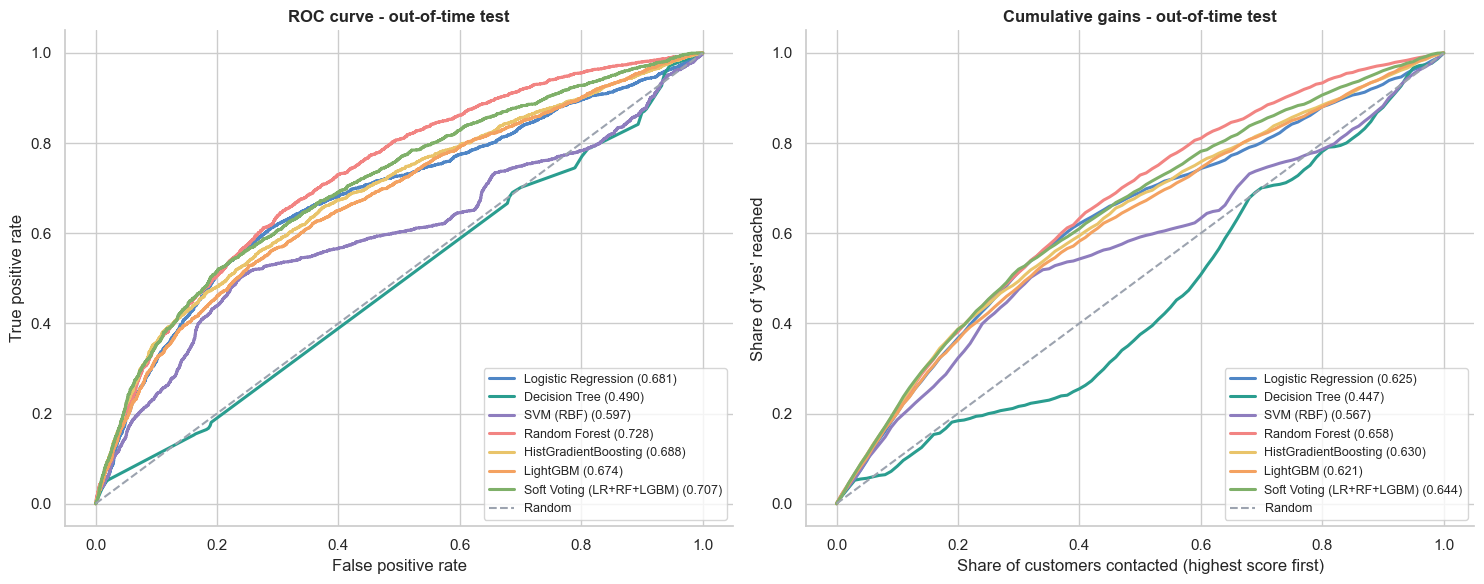

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for n, s in holdout_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[n], lw=2.2, label=f"{n} ({holdout_df.loc[n, 'AUC']:.3f})")
    pts = np.array(export.lift_points(y_test, s))
    axes[1].plot(pts[:, 0], pts[:, 1], color=MODEL_COLORS[n], lw=2.2, label=f"{n} ({holdout_df.loc[n, 'ALIFT']:.3f})")
for ax, t, xl, yl in [(axes[0], 'ROC curve - out-of-time test', 'False positive rate', 'True positive rate'),
                      (axes[1], 'Cumulative gains - out-of-time test', 'Share of customers contacted (highest score first)', "Share of 'yes' reached")]:
    ax.plot([0, 1], [0, 1], '--', color='#9CA3AF', label='Random'); ax.set_title(t, fontweight='bold')
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(loc='lower right', fontsize=9); sns.despine(ax=ax)
plt.tight_layout(); plt.show()

# 5. Uji ketahanan: rolling window seluruh timeline

Hasil satu data uji bisa kebetulan bagus atau jelek. Di sini setiap model dengan hyperparameter terpilih dilatih ulang pada 6 jendela rolling yang menggeser seluruh timeline (jendela 6 blok, uji pada blok berikutnya), mirip pendekatan paper acuan. Rata-rata dan simpangan baku AUC antar lipatan menunjukkan seberapa stabil tiap model terhadap perubahan periode (SVM dilatih pada setiap baris ke-3 di tiap jendela agar waktunya wajar).

Logistic Regression        mean 0.539 std 0.071  (7s)


Decision Tree              mean 0.549 std 0.069  (8s)


SVM (RBF)                  mean 0.532 std 0.060  (21s)


Random Forest              mean 0.568 std 0.079  (27s)


HistGradientBoosting       mean 0.579 std 0.075  (28s)


LightGBM                   mean 0.590 std 0.079  (30s)


Soft Voting (LR+RF+LGBM)   mean 0.582 std 0.080  (46s)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Mean,Std
Logistic Regression,0.439,0.447,0.547,0.617,0.586,0.599,0.539,0.078
Decision Tree,0.445,0.555,0.574,0.483,0.583,0.657,0.549,0.075
SVM (RBF),0.440,0.570,0.572,0.609,0.468,0.535,0.532,0.066
Random Forest,0.427,0.527,0.624,0.570,0.681,0.584,0.568,0.087
HistGradientBoosting,0.421,0.594,0.588,0.579,0.651,0.639,0.579,0.082
LightGBM,0.426,0.572,0.618,0.609,0.654,0.661,0.590,0.087
Soft Voting (LR+RF+LGBM),0.418,0.561,0.604,0.608,0.650,0.651,0.582,0.087


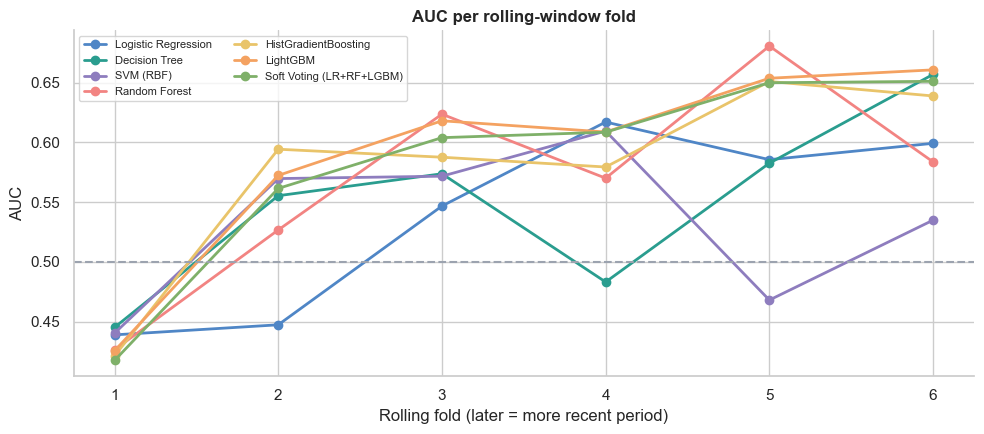

In [7]:
from sklearn.metrics import roc_auc_score
roll_auc = {}
t0 = time.time()
for name in MODEL_NAMES:
    vals = []
    for a, b in roll_splits:
        a_fit = a[::3] if name.startswith('SVM') else a
        m = make_model(name).fit(X.iloc[a_fit], y.iloc[a_fit])
        vals.append(roc_auc_score(y.iloc[b], get_scores(m, X.iloc[b])))
    roll_auc[name] = vals
    print(f"{name:26s} mean {np.mean(vals):.3f} std {np.std(vals):.3f}  ({time.time() - t0:.0f}s)")

roll_df = pd.DataFrame(roll_auc, index=[f'Fold {i}' for i in range(1, 7)]).T
roll_df['Mean'], roll_df['Std'] = roll_df.mean(axis=1), roll_df.iloc[:, :6].std(axis=1)
display(roll_df.style.format('{:.3f}').highlight_max(color='#359FA0', axis=0))

fig, ax = plt.subplots(figsize=(10, 4.5))
for n in MODEL_NAMES:
    ax.plot(range(1, 7), roll_auc[n], marker='o', lw=2, color=MODEL_COLORS[n], label=n)
ax.axhline(0.5, color='#9CA3AF', ls='--'); ax.set_xlabel('Rolling fold (later = more recent period)'); ax.set_ylabel('AUC')
ax.set_title('AUC per rolling-window fold', fontweight='bold'); ax.legend(fontsize=8, ncol=2); sns.despine(); plt.tight_layout(); plt.show()

# 6. Pembanding: split acak stratified

Jika data diacak, baris dari periode yang sama muncul di data latih dan data uji sehingga AUC biasanya lebih tinggi. Angka ini hanya pembanding dan bukan estimasi performa nyata saat model dipakai pada nasabah baru.

,Stratified random split,Out-of-time holdout,Rolling window (mean)
Logistic Regression,0.800,0.681,0.539
Decision Tree,0.799,0.490,0.549
SVM (RBF),0.787,0.597,0.532
Random Forest,0.811,0.728,0.568
HistGradientBoosting,0.806,0.688,0.579
LightGBM,0.809,0.674,0.590
Soft Voting (LR+RF+LGBM),0.809,0.707,0.582


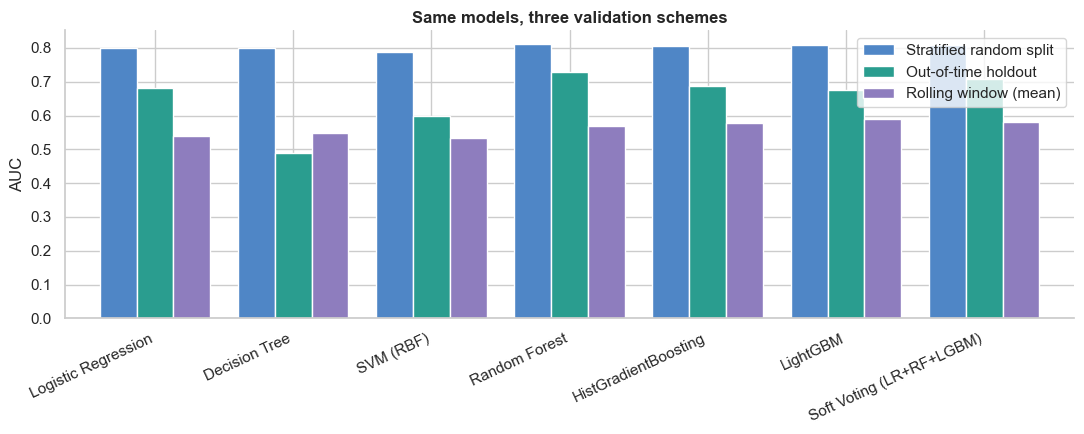

In [8]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
rand_auc = {}
for name in MODEL_NAMES:
    Xf, yf = (Xr_tr.iloc[::3], yr_tr.iloc[::3]) if name.startswith('SVM') else (Xr_tr, yr_tr)
    m = make_model(name).fit(Xf, yf)
    rand_auc[name] = roc_auc_score(yr_te, get_scores(m, Xr_te))
cmp_df = pd.DataFrame({'Stratified random split': pd.Series(rand_auc), 'Out-of-time holdout': holdout_df['AUC'],
                       'Rolling window (mean)': roll_df['Mean']})
display(cmp_df.style.format('{:.3f}').highlight_max(color='#359FA0', axis=0))
cmp_df.plot(kind='bar', figsize=(11, 4.5), color=PALETTE[:3], width=.8); plt.xticks(rotation=25, ha='right'); plt.ylabel('AUC')
plt.title('Same models, three validation schemes', fontweight='bold'); sns.despine(); plt.tight_layout(); plt.show()

# 7. Pemilihan model

Model dipilih berdasarkan rata-rata dua bukti yang tidak bergantung threshold: AUC pada data uji out-of-time dan rata-rata AUC rolling window seluruh timeline. Dengan begitu pilihan tidak hanya bergantung pada satu split.

In [9]:
select_df = pd.DataFrame({'Holdout AUC': holdout_df['AUC'], 'Rolling mean AUC': roll_df['Mean']})
select_df['Selection score'] = select_df.mean(axis=1)
select_df = select_df.sort_values('Selection score', ascending=False)
display(select_df.style.format('{:.3f}').highlight_max(color='#359FA0', axis=0))
BEST = select_df.index[0]
print('Selected model:', BEST)

,Holdout AUC,Rolling mean AUC,Selection score
Random Forest,0.728,0.568,0.648
Soft Voting (LR+RF+LGBM),0.707,0.582,0.645
HistGradientBoosting,0.688,0.579,0.633
LightGBM,0.674,0.590,0.632
Logistic Regression,0.681,0.539,0.610
SVM (RBF),0.597,0.532,0.565
Decision Tree,0.490,0.549,0.520


Selected model: Random Forest


# 8. Titik operasi berbasis kapasitas telepon

Threshold probabilitas 0,5 tidak cocok karena rasio `yes` bergeser antar periode (6% di data latih, 31% di data uji). Tim telemarketing lebih mudah mengatur **berapa persen nasabah yang bisa ditelepon**. Tabel berikut menunjukkan hasil bila hanya nasabah dengan skor tertinggi yang ditelepon.

Contacted (%),Precision,Recall (yes reached),Lift,tp,fp,fn,tn
5,67.0%,10.9%,2.17x,276,136,2263,5561
10,64.4%,20.9%,2.09x,531,293,2008,5404
20,58.8%,38.2%,1.91x,969,679,1570,5018
30,52.7%,51.3%,1.71x,1302,1169,1237,4528
40,48.8%,63.3%,1.58x,1607,1688,932,4009
50,45.0%,72.9%,1.46x,1851,2267,688,3430
70,38.6%,87.7%,1.25x,2226,3540,313,2157


Base rate of 'yes' in test: 30.8% (random calling gives this precision)


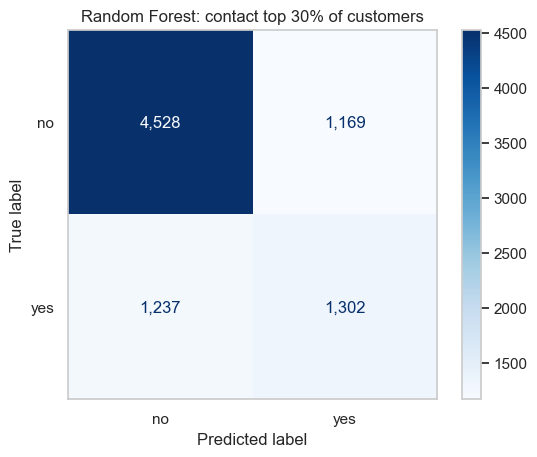

In [10]:
s_best = holdout_scores[BEST]
cap = pd.DataFrame(export.capacity_table(y_test, s_best, ks=[5, 10, 20, 30, 40, 50, 70]))
cap_view = cap.rename(columns={'k': 'Contacted (%)', 'precision': 'Precision', 'recall': 'Recall (yes reached)', 'lift': 'Lift'})
display(cap_view[['Contacted (%)', 'Precision', 'Recall (yes reached)', 'Lift', 'tp', 'fp', 'fn', 'tn']]
        .style.format({'Precision': '{:.1%}', 'Recall (yes reached)': '{:.1%}', 'Lift': '{:.2f}x'}).hide(axis='index'))
print(f"Base rate of 'yes' in test: {y_test.mean():.1%} (random calling gives this precision)")

K = 30
cut = np.quantile(s_best, 1 - K / 100)
cm = confusion_matrix(y_test, (s_best >= cut).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(cmap='Blues', values_format=',d')
plt.title(f'{BEST}: contact top {K}% of customers'); plt.grid(False); plt.show()

# 9. Faktor yang paling berpengaruh

*Permutation importance* pada data uji: tiap fitur mentah diacak, lalu diukur penurunan AUC. Fitur dengan penurunan terbesar paling dibutuhkan model.

feature,auc_drop,std
pdays,0.0625,0.0037
month,0.0601,0.0016
poutcome,0.0248,0.0030
campaign,0.0067,0.0010
default,0.0055,0.0011
age,0.0042,0.0002
job,0.0033,0.0008
contact,0.0023,0.0006
housing,0.0001,0.0003
euribor3m,0.0000,0.0000


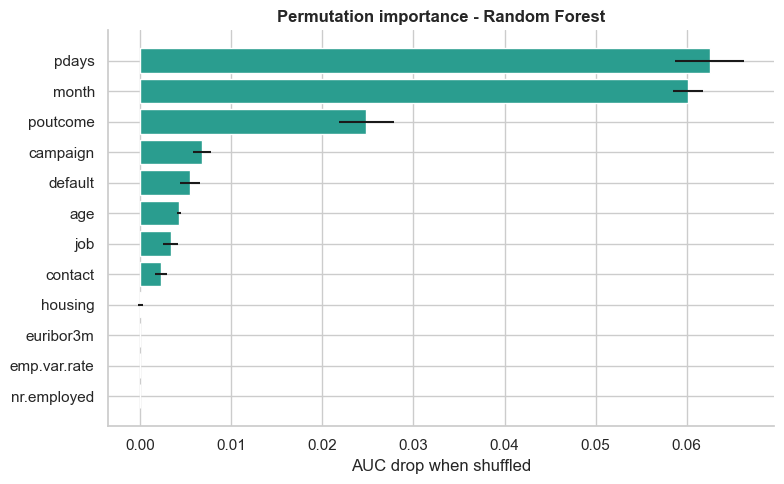

In [11]:
pi = permutation_importance(holdout_models[BEST], X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=4)
imp = pd.DataFrame({'feature': X_test.columns, 'auc_drop': pi.importances_mean, 'std': pi.importances_std}).sort_values('auc_drop', ascending=False)
display(imp.head(10).style.format({'auc_drop': '{:.4f}', 'std': '{:.4f}'}).hide(axis='index'))
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5)); plt.barh(top['feature'], top['auc_drop'], xerr=top['std'], color=PALETTE[1])
plt.xlabel('AUC drop when shuffled'); plt.title(f'Permutation importance - {BEST}', fontweight='bold'); sns.despine(); plt.tight_layout(); plt.show()

# 10. Model final, kalibrasi, dan ekspor

Model terpilih dilatih ulang pada **seluruh** data (termasuk periode terbaru). Skor mentahnya dikalibrasi dengan regresi sigmoid (Platt) yang dilatih pada skor out-of-fold rolling window, sehingga probabilitas mencerminkan perilaku model di periode yang lebih baru. Referensi sebaran skor disimpan agar aplikasi bisa menampilkan posisi persentil nasabah, dan batas default menelepon 30% nasabah teratas dihitung dari sebaran itu.

In [12]:
t0 = time.time()
final_base = make_model(BEST).fit(X, y)
oof_idx, oof_s = oof_scores(lambda: make_model(BEST), X, y, roll_splits)
final_model = PlattCalibrated.from_oof(final_base, y.iloc[oof_idx].values, oof_s)
p_all = final_model.predict_proba(X)[:, 1]
score_ref = np.quantile(p_all, np.linspace(0, 1, 101))
DEFAULT_TOP_K = 30
threshold = float(np.quantile(p_all, 1 - DEFAULT_TOP_K / 100))
print(f"Final model fitted in {time.time() - t0:.0f}s | mean calibrated probability {p_all.mean():.3f} vs actual rate {y.mean():.3f}")
print(f"Default operating point: top {DEFAULT_TOP_K}% -> probability >= {threshold:.3f}")

joblib.dump(final_model, ARTIFACTS / 'model.joblib', compress=3)
reloaded = joblib.load(ARTIFACTS / 'model.joblib')
assert np.allclose(reloaded.predict_proba(X.head(200))[:, 1], p_all[:200])
print('model.joblib saved and reloaded OK')

Final model fitted in 8s | mean calibrated probability 0.115 vs actual rate 0.113
Default operating point: top 30% -> probability >= 0.067


model.joblib saved and reloaded OK


In [13]:
rolling_meta = [{'fold': i + 1, 'test_yes_rate': round(float(y.iloc[b].mean()), 4), 'test_euribor3m': round(float(X.iloc[b]['euribor3m'].mean()), 3)}
                for i, (a, b) in enumerate(roll_splits)]
models_meta = []
for n in MODEL_NAMES:
    tn = tune_df.set_index('Model')
    models_meta.append({
        'name': n, 'selected': n == BEST,
        'holdout': {k: round(float(v), 4) for k, v in holdout_df.loc[n].drop('Fit time (s)').items()},
        'rolling_auc': [round(float(v), 4) for v in roll_auc[n]],
        'rolling_auc_mean': round(float(np.mean(roll_auc[n])), 4), 'rolling_auc_std': round(float(np.std(roll_auc[n], ddof=1)), 4),
        'random_split_auc': round(float(rand_auc[n]), 4),
        'tuning_cv_auc': round(float(tn.loc[n, 'Rolling CV AUC (mean)']), 4) if n in tn.index else None,
        'best_params': {k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in best_params.get(n, {}).items()} if n in best_params else None,
        'roc': export.roc_points(*roc_curve(y_test, holdout_scores[n])[:2]),
        'gains': export.lift_points(y_test, holdout_scores[n]),
    })
metadata = {
    'model_version': date.today().isoformat(), 'model_name': BEST, 'sklearn_version': sklearn.__version__,
    'target': "Customer subscribes to a term deposit ('yes')",
    'features': export.feature_schema(X), 'raw_feature_order': RAW_FEATURES,
    'operating_point': {'default_top_k': DEFAULT_TOP_K, 'threshold': round(threshold, 5)},
    'score_reference': [round(float(v), 5) for v in score_ref],
    'validation': {'holdout_rows': int(len(X_test)), 'train_rows': int(len(X_train)),
                   'holdout_yes_rate': round(float(y_test.mean()), 4), 'train_yes_rate': round(float(y_train.mean()), 4),
                   'rolling_folds': rolling_meta},
    'models': models_meta,
    'uts_baseline': [{'name': n.replace(' (UTS)', ''), 'AUC': float(r.AUC), 'ALIFT': float(r.ALIFT)} for n, r in uts.iterrows()],
    'capacity': export.capacity_table(y_test, s_best),
    'importance': [{'feature': r.feature, 'auc_drop': round(float(r.auc_drop), 5)} for r in imp.itertuples()],
    'eda': export.eda_summary(X, y),
}
(ARTIFACTS / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False))
print('metadata.json:', round((ARTIFACTS / 'metadata.json').stat().st_size / 1024), 'KB | selected:', BEST)

metadata.json: 45 KB | selected: Random Forest


# 11. Ringkasan temuan

1. **Model terpilih: Random Forest.** AUC data uji 0,728, ALIFT 0,658, PR-AUC 0,534. Menelepon 30% nasabah dengan skor tertinggi menjangkau 51,3% nasabah `yes` (lift 1,71x, precision 52,7% pada rasio dasar 30,8%).
2. **AUC tidak melampaui UTS.** LR pada UTS mencatat AUC 0,740 dan ALIFT 0,666, sedangkan Random Forest di sini 0,728 dan 0,658. Selisihnya kecil dan masih dalam rentang variasi antar lipatan (simpangan baku 0,07-0,09), jadi dua hasil tersebut tidak bisa dibedakan secara meyakinkan.
3. **Hasil tuning tidak informatif.** CV AUC rolling window pada periode latih hanya 0,41-0,58 karena periode 2008 hampir satu rezim ekonomi. Hyperparameter hasil tuning sebaiknya dianggap pilihan yang wajar, bukan optimum.
4. **Skema validasi sangat menentukan angka.** AUC split acak 0,79-0,81 untuk semua model, sedangkan out-of-time 0,49-0,73 dan rolling window 0,53-0,59. Split acak terlalu optimis untuk kasus yang dipakai pada nasabah baru.
5. **Decision Tree paling rapuh** (AUC uji 0,490, di bawah acak), sedangkan model berbasis ensemble lebih stabil antar periode.
6. **Fitur paling berpengaruh**: `pdays`, `month`, dan `poutcome` (penurunan AUC 0,063, 0,060, 0,025 bila diacak).
7. **Kalibrasi**: pada model final yang dilatih ulang pada seluruh data, rata-rata probabilitas terkalibrasi 0,115 dibanding rasio yes aktual 0,113. Batas default menelepon 30% teratas setara probabilitas 0,067.
